# Від даних до рішення: невелике демо

Ноутбук до гостьової лекції "Аналітика великих даних та прогнозне
моделювання для інтелектуального прийняття рішень".

Один приклад від початку до кінця: служба доставки вирішує, скільки
кур'єрів поставити на кожен день.

1. створюємо дані: три роки замовлень за день;
2. ділимо їх за часом і будуємо ознаки;
3. порівнюємо базову модель з градієнтним бустингом (MAE, MAPE);
4. прогнозуємо діапазон (квантилі), а не одне число;
5. перетворюємо прогноз на рішення і рахуємо вартість.

**Дані синтетичні.** Вони генеруються в першій комірці з кодом, тож видно
кожне правило, за яким їх побудовано. Це не дані реальної компанії, але
метод той самий, що й на практиці.

Запуск усіх комірок: *Runtime -> Run all* у Google Colab. Це кілька
секунд.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

## 1. Дані

Кількість замовлень за день залежить від чотирьох речей: дня тижня
(п'ятниця й субота найжвавіші), державних свят (замовлень менше; дводенне
свято щороку припадає на інші дати), дощу (замовлень менше, а дощ
частіший у сезон дощів) і випадкового шуму близько 6%.

In [2]:
rng = np.random.default_rng(42)
days = pd.date_range("2023-01-01", "2025-12-31", freq="D")
n = len(days)

# Monday .. Sunday
week = np.array([0.92, 0.95, 1.00, 1.02, 1.18, 1.25, 0.88])
holidays = pd.to_datetime([
    "2023-01-01", "2023-04-21", "2023-04-22", "2023-05-01",
    "2023-06-01", "2023-08-17",
    "2024-01-01", "2024-04-10", "2024-04-11", "2024-05-01",
    "2024-06-01", "2024-08-17",
    "2025-01-01", "2025-03-31", "2025-04-01", "2025-05-01",
    "2025-06-01", "2025-08-17", "2025-11-10"])

df = pd.DataFrame({"date": days})
df["dow"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["holiday"] = df["date"].isin(holidays).astype(int)
wet = df["month"].isin([11, 12, 1, 2, 3])
df["rain"] = (rng.random(n) < np.where(wet, 0.45, 0.12)).astype(int)

level = 1000 * week[df["dow"]]
level = level * (1 - 0.35 * df["holiday"]) * (1 - 0.10 * df["rain"])
noise = rng.normal(0, 0.06, n)
df["orders"] = np.round(level * (1 + noise)).astype(int)

print(df.tail(7).to_string(index=False))

      date  dow  month  holiday  rain  orders
2025-12-25    3     12        0     0    1016
2025-12-26    4     12        0     1    1109
2025-12-27    5     12        0     0    1186
2025-12-28    6     12        0     1     741
2025-12-29    0     12        0     1     839
2025-12-30    1     12        0     0     984
2025-12-31    2     12        0     1     918


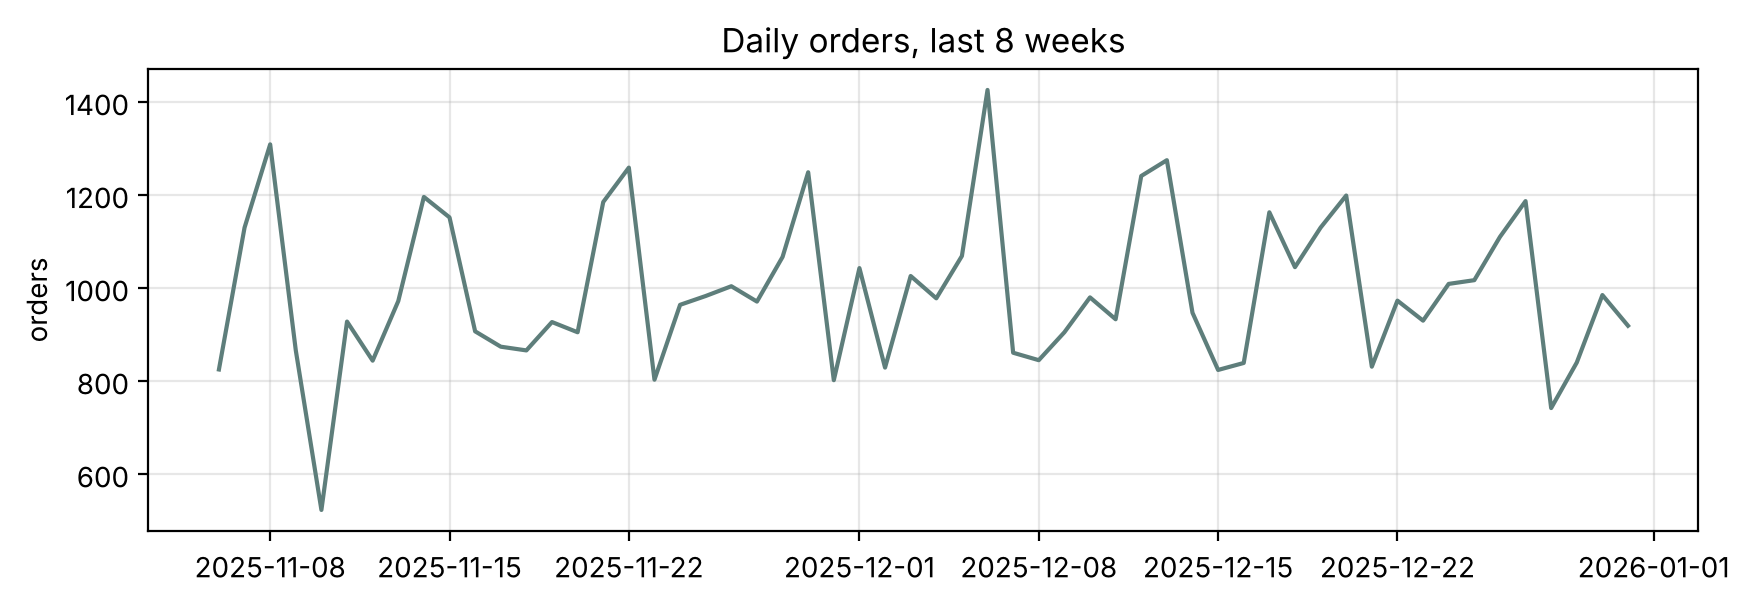

In [3]:
last = df.tail(56)
plt.figure(figsize=(10, 3))
plt.plot(last["date"], last["orders"], color="#5E7E7B")
plt.title("Daily orders, last 8 weeks")
plt.ylabel("orders")
plt.grid(alpha=0.3)
plt.show()

## 2. Ознаки і поділ за часом

Прогнозуємо до 7 днів наперед, тож модель може брати лише те, що відомо
за тиждень: календар, перелік свят, прогноз погоди і замовлення 7 та 14
днів тому (лагові ознаки). Тут вважаємо, що прогноз дощу точний; у житті
він додає власну помилку.

Поділ за часом: навчаємо на минулому, налаштовуємо на валідаційному
періоді, тестуємо один раз на найновіших трьох місяцях.

In [4]:
df["lag7"] = df["orders"].shift(7)
df["lag14"] = df["orders"].shift(14)
df["mean_prev_week"] = df["orders"].shift(7).rolling(7).mean()
df = df.dropna().reset_index(drop=True)

features = ["dow", "month", "holiday", "rain",
            "lag7", "lag14", "mean_prev_week"]

train = df[df["date"] < "2025-07-01"]
valid = df[(df["date"] >= "2025-07-01") & (df["date"] < "2025-10-01")]
test = df[df["date"] >= "2025-10-01"]
print("train:", len(train), " validation:", len(valid),
      " test:", len(test))

train: 898  validation: 92  test: 92


## 3. Базова модель проти градієнтного бустингу

Базова модель каже: "стільки ж, як цього дня минулого тижня". Модель це
градієнтний бустинг зі scikit-learn. Її налаштування (глибина дерев,
кількість дерев) обрано на валідаційному періоді, а тестовий період
використано лише для підсумкових чисел.

In [5]:
def mae(y, p):
    return float(np.mean(np.abs(y - p)))


def mape(y, p):
    return float(np.mean(np.abs(y - p) / y) * 100)


def fit(quantile, data):
    model = HistGradientBoostingRegressor(
        loss="quantile", quantile=quantile, max_iter=200,
        learning_rate=0.05, max_depth=3, min_samples_leaf=10,
        random_state=0)
    return model.fit(data[features], data["orders"])


rows = []
for name, past, part in (("validation", train, valid),
                         ("test", pd.concat([train, valid]), test)):
    y = part["orders"]
    p = fit(0.5, past).predict(part[features])
    rows.append((name, "baseline", mae(y, part["lag7"]),
                 mape(y, part["lag7"])))
    rows.append((name, "gradient boosting", mae(y, p), mape(y, p)))

result = pd.DataFrame(rows, columns=["period", "model", "MAE", "MAPE, %"])
print(result.round(1).to_string(index=False))

    period             model  MAE  MAPE, %
validation          baseline 79.4      8.1
validation gradient boosting 50.5      4.9
      test          baseline 82.8      8.7
      test gradient boosting 41.5      4.2


## 4. Прогноз діапазону

Та сама модель може передбачати квантилі. Навчаємо чотири моделі: для
10-го, 50-го (медіана), 75-го і 90-го перцентилів. Потім на тестовому
періоді перевіряємо, як часто реальне значення потрапляє в діапазон
10-90. Має бути близько 80%.

In [6]:
past = pd.concat([train, valid])
quantiles = (0.10, 0.50, 0.75, 0.90)
pred = {q: fit(q, past).predict(test[features]) for q in quantiles}
y = test["orders"].to_numpy()

inside = np.mean((y >= pred[0.10]) & (y <= pred[0.90]))
below75 = np.mean(y <= pred[0.75])
print(f"Inside the 10-90 range: {inside:.0%} of test days")
print(f"At or below the 75th percentile: {below75:.0%} of test days")

Inside the 10-90 range: 84% of test days
At or below the 75th percentile: 79% of test days


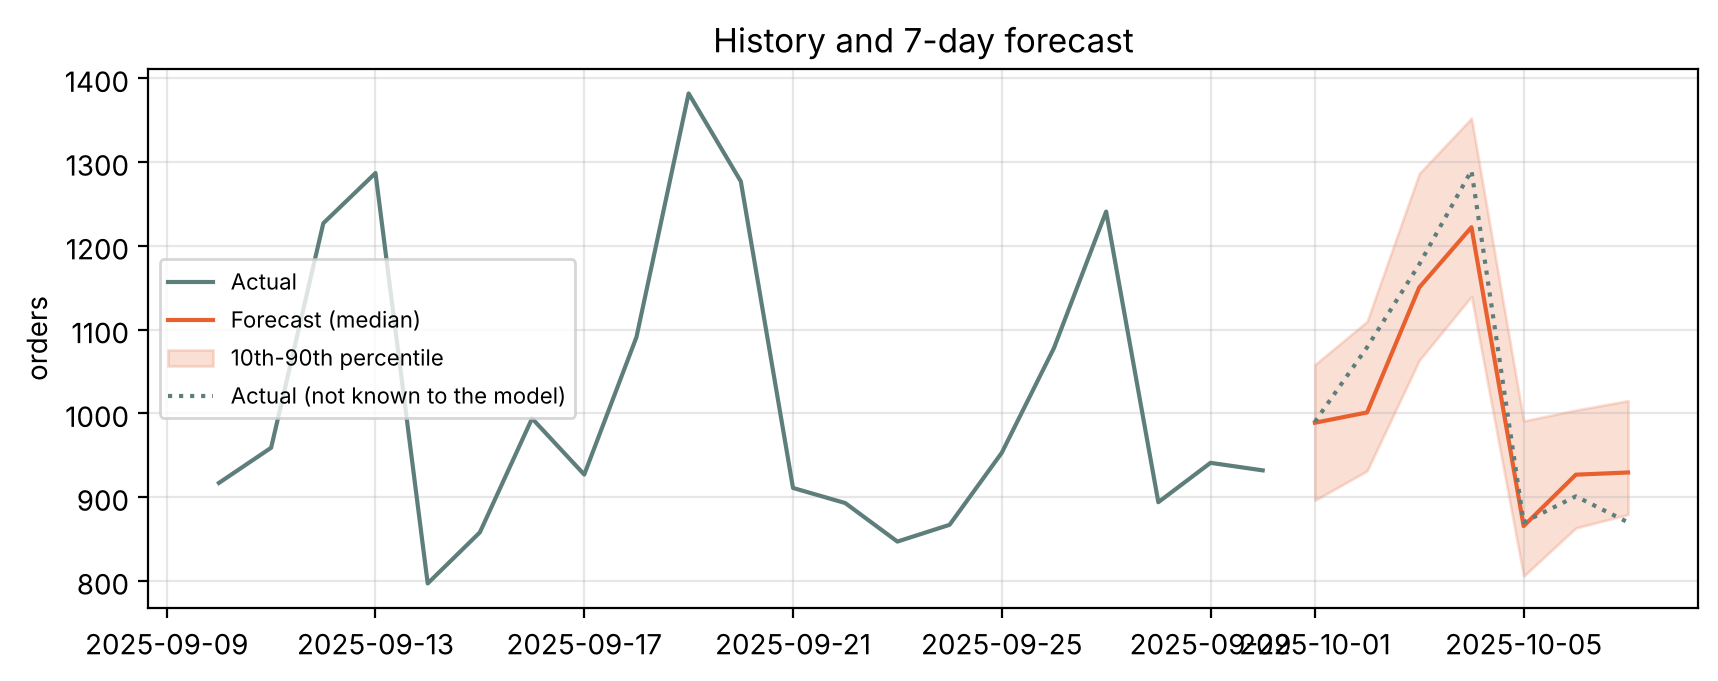

In [7]:
hist = past.tail(21)
week7 = test.head(7)
k = slice(0, 7)

plt.figure(figsize=(10, 3.5))
plt.plot(hist["date"], hist["orders"], color="#5E7E7B", label="Actual")
plt.plot(week7["date"], pred[0.50][k], color="#E9602F",
         label="Forecast (median)")
plt.fill_between(week7["date"], pred[0.10][k], pred[0.90][k],
                 color="#E9602F", alpha=0.2, label="10th-90th percentile")
plt.plot(week7["date"], week7["orders"], color="#5E7E7B",
         linestyle=":", label="Actual (not known to the model)")
plt.title("History and 7-day forecast")
plt.ylabel("orders")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

## 5. Від прогнозу до рішення

Кур'єрів ставимо під заплановану кількість замовлень. Кожне замовлення,
яке не змогли доставити, коштує 3 одиниці; кожне незадіяне місце коштує
1 одиницю. Правило продавця газет (newsvendor) дає квантиль, на який
треба планувати: 3 / (3 + 1) = 0,75.

Нижче загальна вартість за тестовий період для чотирьох планів.

In [8]:
COST_SHORT = 3   # one lost order
COST_EXTRA = 1   # one unused delivery slot


def total_cost(plan):
    short = np.maximum(y - plan, 0)
    extra = np.maximum(plan - y, 0)
    return int(round(np.sum(COST_SHORT * short + COST_EXTRA * extra)))


plans = [("Baseline: same day last week", test["lag7"].to_numpy()),
         ("Model, median (50th percentile)", pred[0.50]),
         ("Model, 75th percentile", pred[0.75]),
         ("Model, 90th percentile", pred[0.90])]
costs = pd.DataFrame(
    [(name, total_cost(plan)) for name, plan in plans],
    columns=["plan", "total cost"])
base = costs["total cost"].iloc[0]
costs["vs baseline, %"] = (
    (costs["total cost"] / base * 100 - 100).round().astype(int))
print(costs.to_string(index=False))

                           plan  total cost  vs baseline, %
   Baseline: same day last week       15117               0
Model, median (50th percentile)        8650             -43
         Model, 75th percentile        6149             -59
         Model, 90th percentile        7980             -47


## На що звернути увагу

- Модель перемагає базову і за помилкою, і за вартістю.
- З тією самою моделлю план на 75-й перцентиль дешевший, ніж план на
  медіану. Правило рішення дає другу економію.
- 90-й перцентиль тут надто обережний: платимо за простій кур'єрів.
- Прогноз дає діапазон, а вартість обирає точку.

## Спробуйте самі

1. Змініть `COST_SHORT` на 9. Який квантиль тепер найкращий?
   (9 / (9 + 1) = 0,9)
2. Приберіть `"holiday"` з `features`. Що стане з помилкою?
3. Замініть поділ за часом на випадковий. Чому числа стають кращими і
   чому це оманливо?
4. Додайте в дані повільне зростання (наприклад `* (1 + 0.0004 * t)`).
   Дерева не вміють продовжувати тренд. Як це виправити?